In [10]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

sns.set_theme(style="whitegrid", palette="muted")

df = pd.read_csv('Titanic-Dataset.csv')
print(f"Размерность датасета: {df.shape[0]} строк, {df.shape[1]} столбцов")
print(f"Количество полных дубликатов: {df.duplicated().sum()}\n")

summary = pd.DataFrame({
    'Тип данных': df.dtypes,
    'Пропуски (шт.)': df.isnull().sum(),
    'Пропуски (%)': (df.isnull().sum() / len(df) * 100).round(2),
    'Уникальных значений': df.nunique()
})
display(summary)
display(df.head())

Размерность датасета: 891 строк, 12 столбцов
Количество полных дубликатов: 0



,Тип данных,Пропуски (шт.),Пропуски (%),Уникальных значений
PassengerId,int64,0,0.00,891
Survived,int64,0,0.00,2
Pclass,int64,0,0.00,3
Name,object,0,0.00,891
Sex,object,0,0.00,2
Age,float64,177,19.87,88
SibSp,int64,0,0.00,7
Parch,int64,0,0.00,7
Ticket,object,0,0.00,681
Fare,float64,0,0.00,248


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


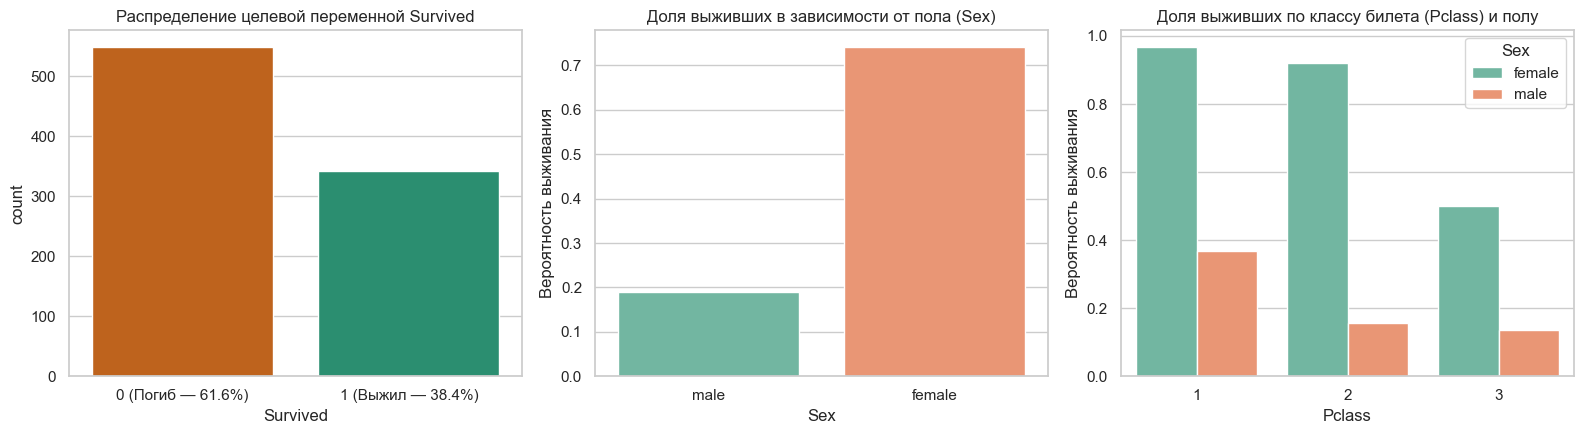

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.countplot(data=df, x='Survived', ax=axes[0], palette=['#d95f02', '#1b9e77'])
axes[0].set_title('Распределение целевой переменной Survived')
axes[0].set_xticklabels(['0 (Погиб — 61.6%)', '1 (Выжил — 38.4%)'])

sns.barplot(data=df, x='Sex', y='Survived', ax=axes[1], palette='Set2', errorbar=None)
axes[1].set_title('Доля выживших в зависимости от пола (Sex)')
axes[1].set_ylabel('Вероятность выживания')

sns.barplot(data=df, x='Pclass', y='Survived', hue='Sex', ax=axes[2], palette='Set2', errorbar=None)
axes[2].set_title('Доля выживших по классу билета (Pclass) и полу')
axes[2].set_ylabel('Вероятность выживания')

plt.tight_layout()
plt.show()

### Выводы по первичному анализу данных (EDA)

1. **Общая характеристика и дубликаты:** Датасет содержит **891 объект** и **12 признаков** (включая целевую переменную `Survived`). Полные дубликаты строк отсутствуют (`0`).
2. **Распределение целевой переменной (`Survived`):** Наблюдается умеренный дисбаланс классов:
   * Класс `0` (пассажир погиб): **549 человек (61.62%)**;
   * Класс `1` (пассажир выжил): **342 человека (38.38%)**.
   Из-за дисбаланса классов метрика `Accuracy` не отражает реальную способность модели находить выживших, поэтому в качестве основной метрики используется **F1-score** для класса `Survived = 1`, гармонически усредняющая точность (`Precision`) и полноту (`Recall`).
3. **Анализ пропущенных значений:** Пропуски присутствуют в трех признаках:
   * `Age` (возраст): **177 пропусков (19.87%)** — требует импутации медианой;
   * `Embarked` (порт посадки): **2 пропуска (0.22%)** — требует импутации наиболее частым значением (модой `'S'`);
   * `Cabin` (номер каюты): **687 пропусков (77.10%)** — содержит критическую долю пропусков и 147 уникальных текстовых номеров на 204 записи, поэтому исключается из выборки.
4. **Признаки, ведущие к утечке информации или бессмысленному запоминанию объектов:** Признаки `PassengerId` (891 уникальное значение — технический индекс строки), `Name` (891 уникальное имя) и `Ticket` (681 уникальный номер билета) однозначно идентифицируют конкретных пассажиров. Их включение в модель приведет к тривиальному запоминанию объектов обучающей выборки (переобучению) вместо выявления обобщающих закономерностей, поэтому данные столбцы исключаются.
5. **Ключевые зависимости в данных:** Выживаемость сильно зависит от пола пассажира (`Sex`) и социально-экономического статуса (`Pclass`). Среди женщин выжили **74.20%**, тогда как среди мужчин — лишь **18.89%** (правило эвакуации «женщины и дети вперед»). В 1-м классе доля выживших составила **62.96%**, во 2-м — **47.28%**, а в 3-м классе — только **24.24%**.

In [12]:
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
X = df[features].copy()
y = df['Survived'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Обучающая выборка (Train): {X_train.shape[0]} объектов (доля класса 1: {y_train.mean():.4f})")
print(f"Тестовая выборка (Test):   {X_test.shape[0]} объектов (доля класса 1: {y_test.mean():.4f})")

numeric_features = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
categorical_features = ['Sex', 'Embarked']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(drop='first', sparse_output=False))
        ]), categorical_features)
    ]
)

Обучающая выборка (Train): 712 объектов (доля класса 1: 0.3834)
Тестовая выборка (Test):   179 объектов (доля класса 1: 0.3855)


### Обоснование способов предобработки данных и масштабирования

1. **Стратифицированное разбиение выборки:** Данные разделены на обучающую (`712` объектов, 80%) и тестовую (`179` объектов, 20%) выборки с параметрами `stratify=y` и `random_state=42`. Стратификация гарантирует идентичное соотношение классов в обеих выборках (доля выживших составляет `38.34%` в `train` и `38.55%` в `test`).
2. **Обработка пропусков (`SimpleImputer`):**
   * Пропуски в числовом признаке `Age` заполняются **медианой** обучающей выборки (`28.0` лет), так как медиана робастна (устойчива) к выбросам и асимметрии распределения возраста.
   * Пропуски в категориальном признаке `Embarked` заполняются **модой** (`strategy='most_frequent'`, значение `'S'`).
3. **Кодирование категориальных признаков (`OneHotEncoder`):** Номинальные признаки `Sex` и `Embarked` преобразуются методом One-Hot Encoding с параметром `drop='first'` (формируются бинарные признаки `Sex_male`, `Embarked_Q`, `Embarked_S`), что предотвращает мультиколлинеарность.
4. **Защита от утечки данных:** Все этапы предобработки инкапсулированы в `ColumnTransformer` и `Pipeline`. Статистики импутации и стандартизации вычисляются исключительно на обучающей выборке (`X_train`), а к тестовой выборке применяются только через метод `.transform()`.
5. **Роль масштабирования признаков (`StandardScaler`) для различных алгоритмов:**
   * **Деревья решений и ансамбли на их основе (`Decision Tree`, `Random Forest`, `Gradient Boosting`) не чувствительны к масштабу признаков**, так как строят разбиения по пороговым неравенствам вдоль отдельных координатных осей (вида $x_j \le t$). Монотонное масштабирование лишь пропорционально сдвигает порог $t$, не меняя структуру разбиения и критерий Джини.
   * **Для метрических и ядерных алгоритмов (`KNN` и `SVM`) масштабирование критически важно.** Признаки имеют несопоставимые единицы измерения: стоимость билета `Fare` варьируется от `0` до `512.33`, возраст `Age` — от `0.42` до `80`, а бинарный пол `Sex_male` принимает значения `0` или `1`. Поскольку алгоритм **KNN** вычисляет евклидово расстояние $d(x, z) = \sqrt{\sum_{j=1}^m (x_j - z_j)^2}$, без стандартизации признак `Fare` будет полностью доминировать в сумме квадратов разностей, подавляя вклад пола и класса каюты. Аналогично в **SVM** с RBF-ядром $K(x, z) = \exp(-\gamma \|x - z\|^2)$ и регуляризацией ширины разделяющей полосы отсутствие единого масштаба искажает геометрию гиперплоскости.

In [13]:
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te, prep=preprocessor):
    pipe = Pipeline([('prep', prep), ('model', model)])
    pipe.fit(X_tr, y_tr)
    
    pred_tr = pipe.predict(X_tr)
    pred_te = pipe.predict(X_te)
    
    metrics = {
        'Model': name,
        'Train_Acc': accuracy_score(y_tr, pred_tr),
        'Train_F1': f1_score(y_tr, pred_tr, zero_division=0),
        'Test_Acc': accuracy_score(y_te, pred_te),
        'Test_Precision': precision_score(y_te, pred_te, zero_division=0),
        'Test_Recall': recall_score(y_te, pred_te, zero_division=0),
        'Test_F1': f1_score(y_te, pred_te, zero_division=0),
        'CM': confusion_matrix(y_te, pred_te),
        'Pipeline': pipe,
        'Pred_Test': pred_te
    }
    print(f"{name}")
    print(f"Train -> Accuracy: {metrics['Train_Acc']:.4f} | F1: {metrics['Train_F1']:.4f}")
    print(f"Test  -> Accuracy: {metrics['Test_Acc']:.4f} | Precision: {metrics['Test_Precision']:.4f} | "
          f"Recall: {metrics['Test_Recall']:.4f} | F1: {metrics['Test_F1']:.4f}")
    tn, fp, fn, tp = metrics['CM'].ravel()
    print(f"Confusion Matrix (Test): TN={tn}, FP={fp}, FN={fn}, TP={tp}\n")
    return metrics

dummy_res = evaluate_model(
    'Dummy Baseline', DummyClassifier(strategy='most_frequent'),
    X_train, y_train, X_test, y_test
)

Dummy Baseline
Train -> Accuracy: 0.6166 | F1: 0.0000
Test  -> Accuracy: 0.6145 | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000
Confusion Matrix (Test): TN=110, FP=0, FN=69, TP=0



### Анализ Dummy Baseline и интерпретация ошибок (FP и FN)

1. **Оценка Dummy Baseline:** Тривиальный классификатор (`strategy='most_frequent'`) всегда предсказывает мажоритарный класс `0` («пассажир погиб»). На тестовой выборке он угадывает все 110 случаев гибели (`TN = 110, FP = 0`), за счет чего достигает **`Accuracy = 0.6145` (61.45%)**. Однако он не обнаруживает ни одного выжившего пассажира (`TP = 0, FN = 69`), вследствие чего **`Precision = 0.0000`, `Recall = 0.0000` и `F1-score = 0.0000`**. Это подтверждает, что при дисбалансе классов метрика `Accuracy` неинформативна без анализа `F1-score`.
2. **Интерпретация элементов Confusion Matrix в контексте задачи:**
   * **True Negative ($TN$):** Пассажир погиб (`0`), и модель корректно предсказала `0`.
   * **True Positive ($TP$):** Пассажир выжил (`1`), и модель корректно предсказала `1`.
   * **False Positive ($FP$, ошибка I рода):** Пассажир в действительности **погиб (`0`)**, но модель ошибочно предсказала его **выживание (`1`)**. Рост числа ошибок $FP$ снижает метрику **Precision** ($\frac{TP}{TP + FP}$), характеризующую точность предсказаний положительного класса.
   * **False Negative ($FN$, ошибка II рода):** Пассажир в действительности **выжил (`1`)**, но модель ошибочно классифицировала его как **погибшего (`0`)**. Рост числа ошибок $FN$ снижает метрику **Recall** ($\frac{TP}{TP + FN}$), характеризующую полноту обнаружения выживших пассажиров.

In [14]:
dt_overfit = evaluate_model(
    'Decision Tree (Unconstrained, max_depth=None)',
    DecisionTreeClassifier(random_state=42),
    X_train, y_train, X_test, y_test
)

dt_res = evaluate_model(
    'Decision Tree',
    DecisionTreeClassifier(max_depth=7, min_samples_leaf=3, random_state=42),
    X_train, y_train, X_test, y_test
)

rf_res = evaluate_model(
    'Random Forest',
    RandomForestClassifier(n_estimators=300, max_depth=6, class_weight='balanced', random_state=42),
    X_train, y_train, X_test, y_test
)

gb_res = evaluate_model(
    'Gradient Boosting',
    GradientBoostingClassifier(n_estimators=200, learning_rate=0.12, max_depth=4, subsample=0.8, random_state=42),
    X_train, y_train, X_test, y_test
)

svm_res = evaluate_model(
    'SVM (RBF)',
    SVC(C=1.0, kernel='rbf', random_state=42),
    X_train, y_train, X_test, y_test
)

knn_res = evaluate_model(
    'KNN (k=5)',
    KNeighborsClassifier(n_neighbors=5),
    X_train, y_train, X_test, y_test
)

prep_unscaled = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numeric_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(drop='first', sparse_output=False))
    ]), categorical_features)
])
print("Проверка SVM и KNN БЕЗ масштабирования признаков")
_ = evaluate_model('SVM (БЕЗ масштабирования)', SVC(C=1.0, kernel='rbf', random_state=42), X_train, y_train, X_test, y_test, prep=prep_unscaled)
_ = evaluate_model('KNN (БЕЗ масштабирования)', KNeighborsClassifier(n_neighbors=5), X_train, y_train, X_test, y_test, prep=prep_unscaled)

Decision Tree (Unconstrained, max_depth=None)
Train -> Accuracy: 0.9831 | F1: 0.9776
Test  -> Accuracy: 0.8212 | Precision: 0.7937 | Recall: 0.7246 | F1: 0.7576
Confusion Matrix (Test): TN=97, FP=13, FN=19, TP=50

Decision Tree
Train -> Accuracy: 0.8820 | F1: 0.8333
Test  -> Accuracy: 0.8156 | Precision: 0.8103 | Recall: 0.6812 | F1: 0.7402
Confusion Matrix (Test): TN=99, FP=11, FN=22, TP=47

Random Forest
Train -> Accuracy: 0.8890 | F1: 0.8534
Test  -> Accuracy: 0.8156 | Precision: 0.7647 | Recall: 0.7536 | F1: 0.7591
Confusion Matrix (Test): TN=94, FP=16, FN=17, TP=52

Gradient Boosting
Train -> Accuracy: 0.9775 | F1: 0.9704
Test  -> Accuracy: 0.8268 | Precision: 0.7879 | Recall: 0.7536 | F1: 0.7704
Confusion Matrix (Test): TN=96, FP=14, FN=17, TP=52

SVM (RBF)
Train -> Accuracy: 0.8413 | F1: 0.7797
Test  -> Accuracy: 0.8324 | Precision: 0.8305 | Recall: 0.7101 | F1: 0.7656
Confusion Matrix (Test): TN=100, FP=10, FN=20, TP=49

KNN (k=5)
Train -> Accuracy: 0.8553 | F1: 0.8031
Test  ->

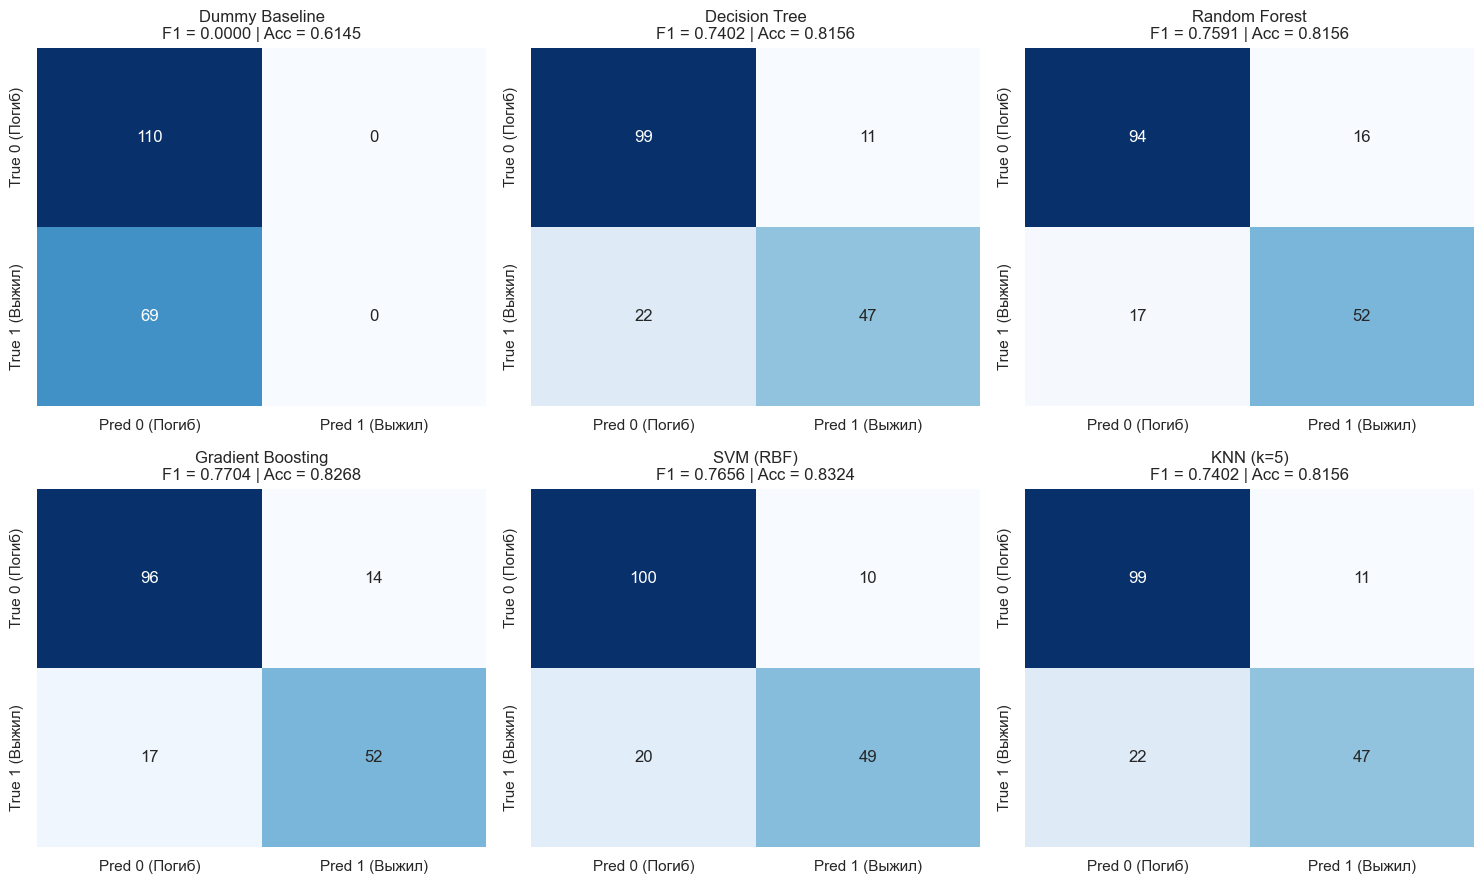

In [15]:
all_results = [dummy_res, dt_res, rf_res, gb_res, svm_res, knn_res]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, res in zip(axes.flatten(), all_results):
    sns.heatmap(
        res['CM'], annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
        xticklabels=['Pred 0 (Погиб)', 'Pred 1 (Выжил)'],
        yticklabels=['True 0 (Погиб)', 'True 1 (Выжил)']
    )
    ax.set_title(f"{res['Model']}\nF1 = {res['Test_F1']:.4f} | Acc = {res['Test_Acc']:.4f}")
plt.tight_layout()
plt.show()

### Анализ результатов обучения моделей и матриц ошибок

1. **Decision Tree (Дерево решений) и анализ переобучения:**
   * Дерево без ограничений глубины (`max_depth=None`) демонстрирует сильное **переобучение**: на обучающей выборке достигается `Train F1 = 0.9776` (`Train Accuracy = 0.9831`), тогда как на тестовой выборке метрика падает до `Test F1 = 0.7576` (разрыв свыше **22 процентных пунктов**). Дерево дробит пространство признаков до единичных листьев, запоминая шум обучающей выборки.
   * При введении структурной регуляризации (`max_depth=7, min_samples_leaf=3`) переобучение существенно подавляется: `Train F1 = 0.8333`, **`Test F1 = 0.7402`** (`Test Accuracy = 0.8156`, `Precision = 0.8103`, `Recall = 0.6812`). По матрице ошибок ($TN=99, FP=11, FN=22, TP=47$) видно, что дерево осторожно предсказывает выживание, допуская в два раза больше пропусков выживших ($FN=22$), чем ложных срабатываний ($FP=11$).
2. **Random Forest (Случайный лес):**
   * Ансамбль из 300 деревьев (`max_depth=6, class_weight='balanced'`) показывает **`Test F1 = 0.7591`** (`Train F1 = 0.8534`, `Test Accuracy = 0.8156`). За счет усреднения прогнозов независимых деревьев на бутстрэп-выборках и балансировки весов классов модель значительно повысила полноту: **`Recall` вырос с `0.6812` до `0.7536`** ($TP=52, FN=17, FP=16$).
3. **Gradient Boosting (Градиентный бустинг):**
   * Последовательный ансамбль из 200 деревьев (`learning_rate=0.12, max_depth=4, subsample=0.8`) демонстрирует **наилучшее значение основной метрики в работе: `Test F1 = 0.7704`** (`Test Accuracy = 0.8268`, `Precision = 0.7879`, `Recall = 0.7536`). По сравнению с Random Forest градиентный бустинг сохранил высокую полноту обнаружения выживших ($TP=52, FN=17$), но за счет последовательной минимизации остатков ошибки сократил количество ложноположительных срабатываний ($FP$ снизилось с $16$ до $14$).
4. **Support Vector Machine (SVM с RBF-ядром):**
   * Метод опорных векторов показал **наивысшую общую точность `Test Accuracy = 0.8324`** и **наивысший `Precision = 0.8305`** при втором результате по основной метрике **`Test F1 = 0.7656`** ($TN=100, FP=10, FN=20, TP=49$). Модель совершает минимальное среди всех алгоритмов число ошибок $FP = 10$ и практически не имеет разрыва между обучением и тестом (`Train F1 = 0.7797` vs `Test F1 = 0.7656`).
   * **Влияние масштабирования:** Без `StandardScaler` качество SVM падает с **`F1 = 0.7656` до `F1 = 0.3200`** (`Accuracy = 0.6201`), что экспериментально подтверждает необходимость стандартизации для ядерных методов.
5. **K-Nearest Neighbors (`KNN`, $k=5$):**
   * На стандартизированных признаках алгоритм ближайших соседей достигает **`Test F1 = 0.7402`** (`Test Accuracy = 0.8156`, `Precision = 0.8103`, `Recall = 0.6812`, $TN=99, FP=11, FN=22, TP=47$).
   * **Влияние масштабирования:** Без `StandardScaler` метрика `KNN` падает с **`F1 = 0.7402` до `F1 = 0.5649`** (`Accuracy = 0.6816`), не преодолевая порог $0.70$, поскольку евклидово расстояние полностью искажается ненормированным признаком стоимости билета `Fare`.

In [16]:
comparison_df = pd.DataFrame([
    {
        'Модель': r['Model'],
        'Train Accuracy': round(r['Train_Acc'], 4),
        'Train F1': round(r['Train_F1'], 4),
        'Test Accuracy': round(r['Test_Acc'], 4),
        'Test Precision': round(r['Test_Precision'], 4),
        'Test Recall': round(r['Test_Recall'], 4),
        'Test F1-score': round(r['Test_F1'], 4),
        'Порог F1 > 0.70': 'Да' if r['Test_F1'] > 0.70 else 'Нет'
    }
    for r in all_results
]).sort_values(by='Test F1-score', ascending=False)

display(comparison_df)

,Модель,Train Accuracy,Train F1,Test Accuracy,Test Precision,Test Recall,Test F1-score,Порог F1 > 0.70
3,Gradient Boosting,0.9775,0.9704,0.8268,0.7879,0.7536,0.7704,Да
4,SVM (RBF),0.8413,0.7797,0.8324,0.8305,0.7101,0.7656,Да
2,Random Forest,0.8890,0.8534,0.8156,0.7647,0.7536,0.7591,Да
1,Decision Tree,0.8820,0.8333,0.8156,0.8103,0.6812,0.7402,Да
5,KNN (k=5),0.8553,0.8031,0.8156,0.8103,0.6812,0.7402,Да
0,Dummy Baseline,0.6166,0.0000,0.6145,0.0000,0.0000,0.0000,Нет


,Признак,Decision Tree,Random Forest,Gradient Boosting
5,Sex_male,0.4705,0.4084,0.3061
4,Fare,0.1569,0.1941,0.2685
1,Age,0.1582,0.1419,0.2325
0,Pclass,0.1615,0.1225,0.1088
2,SibSp,0.0163,0.0521,0.0341
3,Parch,0.0034,0.0401,0.0227
7,Embarked_S,0.0331,0.0279,0.0214
6,Embarked_Q,0.0000,0.0129,0.0059


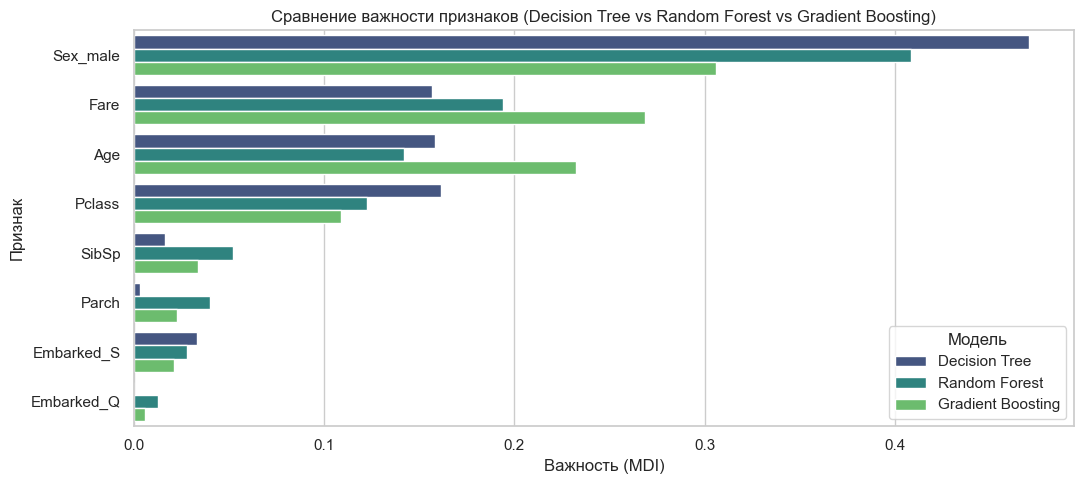

In [17]:
feature_names = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']

fi_df = pd.DataFrame({
    'Признак': feature_names,
    'Decision Tree': dt_res['Pipeline'].named_steps['model'].feature_importances_,
    'Random Forest': rf_res['Pipeline'].named_steps['model'].feature_importances_,
    'Gradient Boosting': gb_res['Pipeline'].named_steps['model'].feature_importances_
}).sort_values(by='Gradient Boosting', ascending=False)

display(fi_df.round(4))

fi_melted = fi_df.melt(id_vars='Признак', var_name='Модель', value_name='Важность (MDI)')
plt.figure(figsize=(11, 5))
sns.barplot(data=fi_melted, x='Важность (MDI)', y='Признак', hue='Модель', palette='viridis')
plt.title('Сравнение важности признаков (Decision Tree vs Random Forest vs Gradient Boosting)')
plt.tight_layout()
plt.show()

### Выводы по анализу важности признаков (Feature Importance)

1. **Ключевые признаки:** Во всех трех деревянных моделях доминируют четыре признака: **пол пассажира (`Sex_male`)**, **стоимость билета (`Fare`)**, **возраст (`Age`)** и **класс каюты (`Pclass`)**, на которые суммарно приходится от **86.7%** (в `Random Forest`) до **94.7%** (в `Decision Tree`) всей информативности разбиений.
2. **Сравнение Decision Tree, Random Forest и Gradient Boosting:**
   * В одиночном дереве (**`Decision Tree`**) наблюдается резкая концентрация важности в одном корневом признаке `Sex_male` (**47.05%**), а остальные три главных признака (`Pclass` — 16.15%, `Age` — 15.82%, `Fare` — 15.69%) делят оставшуюся долю практически поровну, тогда как второстепенные признаки (`Parch`, `Embarked_Q`) почти не задействуются.
   * В случайном лесе (**`Random Forest`**) за счет случайного выбора подмножества признаков в каждом узле (`max_features='sqrt'`) важность распределяется более сглаженно: доля `Sex_male` снижается до **40.84%**, при этом возрастает вклад цены билета `Fare` (**19.41%**) и признаков размера семьи (`SibSp` — 5.21%, `Parch` — 4.01%).
   * В градиентном бустинге (**`Gradient Boosting`**) после учета базового разделения по полу (`Sex_male` — **30.58%**) последующие деревья активно используют непрерывные признаки **`Fare` (26.77%)** и **`Age` (23.34%)** для тонкой корректировки остатков ошибки в сложных подгруппах пассажиров.
3. **Сопоставление с выводами первичного анализа (EDA):** Иерархия важности признаков полностью подтверждает наблюдения, полученные на этапе EDA: пол (`Sex`) и социально-экономический статус (`Pclass` и тесно коррелирующий с ним `Fare`) являются главными статистическими предикторами выживания на «Титанике».
4. **Причинно-следственная связь vs корреляция:**
   * **Высокая важность признака для модели не означает, что он является прямой физической причиной выживания.**
   * Например, признак `Fare` (стоимость билета) занимает 2-е место по важности в ансамблях, однако сама цена билета не влияет на физическую выживаемость человека. `Fare` и `Pclass` выступают **прокси-переменными (косвенными индикаторами)** реальных физических факторов: близости кают 1-го класса к верхним шлюпочным палубам и очередности допуска пассажиров к спасательным шлюпкам. Аналогично влияние признаков `Sex_male` и `Age` обусловлено не биологическими причинами, а социальным регламентом эвакуации («женщины и дети вперед»).

In [18]:
test_analysis = df.loc[X_test.index].copy()
test_analysis['y_true'] = y_test
test_analysis['y_pred'] = gb_res['Pred_Test']
test_analysis['y_prob'] = gb_res['Pipeline'].predict_proba(X_test)[:, 1].round(3)
test_analysis['Error_Type'] = 'Correct'
test_analysis.loc[(test_analysis['y_true'] == 0) & (test_analysis['y_pred'] == 1), 'Error_Type'] = 'FP (Ложно выжил)'
test_analysis.loc[(test_analysis['y_true'] == 1) & (test_analysis['y_pred'] == 0), 'Error_Type'] = 'FN (Ложно погиб)'

print("Распределение типов предсказаний на тестовой выборке:")
print(test_analysis['Error_Type'].value_counts(), "\n")

group_errors = test_analysis.groupby(['Sex', 'Pclass']).apply(
    lambda g: pd.Series({
        'Всего в тесте': len(g),
        'Ошибок всего': (g['y_true'] != g['y_pred']).sum(),
        'Доля ошибок (%)': round((g['y_true'] != g['y_pred']).mean() * 100, 1),
        'FP (погиб -> предск. 1)': (g['Error_Type'] == 'FP (Ложно выжил)').sum(),
        'FN (выжил -> предск. 0)': (g['Error_Type'] == 'FN (Ложно погиб)').sum()
    })
)
display(group_errors)

errors_sample = test_analysis[test_analysis['Error_Type'] != 'Correct'][
    ['PassengerId', 'Name', 'Sex', 'Age', 'Pclass', 'SibSp', 'Parch', 'Fare', 'y_true', 'y_pred', 'y_prob', 'Error_Type']
]
print("\nПримеры ошибочно классифицированных объектов:")
display(errors_sample.head(10))

Распределение типов предсказаний на тестовой выборке:
Error_Type
Correct             148
FN (Ложно погиб)     17
FP (Ложно выжил)     14
Name: count, dtype: int64 



Всего в тесте  Ошибок всего  Доля ошибок (%)  \
Sex    Pclass                                                 
female 1                15.0           1.0              6.7   
       2                18.0           1.0              5.6   
       3                28.0           5.0             17.9   
male   1                30.0          10.0             33.3   
       2                16.0           3.0             18.8   
       3                72.0          11.0             15.3   

               FP (погиб -> предск. 1)  FN (выжил -> предск. 0)  
Sex    Pclass                                                    
female 1                           1.0                      0.0  
       2                           1.0                      0.0  
       3                           3.0                      2.0  
male   1                           5.0                      5.0  
       2                           0.0                      3.0  
       3                           4.0                      7.0


Примеры ошибочно классифицированных объектов:


,PassengerId,Name,Sex,Age,Pclass,SibSp,Parch,Fare,y_true,y_pred,y_prob,Error_Type
553,554,"Leeni, Mr. Fahim (""Philip Zenni"")",male,22.0,3,0,0,7.2250,1,0,0.082,FN (Ложно погиб)
559,560,"de Messemaeker, Mrs. Guillaume Joseph (Emma)",female,36.0,3,1,0,17.4000,1,0,0.074,FN (Ложно погиб)
536,537,"Butt, Major. Archibald Willingham",male,45.0,1,0,0,26.5500,0,1,0.916,FP (Ложно выжил)
698,699,"Thayer, Mr. John Borland",male,49.0,1,1,1,110.8833,0,1,0.757,FP (Ложно выжил)
279,280,"Abbott, Mrs. Stanton (Rosa Hunt)",female,35.0,3,1,1,20.2500,1,0,0.237,FN (Ложно погиб)
712,713,"Taylor, Mr. Elmer Zebley",male,48.0,1,1,0,52.0000,1,0,0.113,FN (Ложно погиб)
455,456,"Jalsevac, Mr. Ivan",male,29.0,3,0,0,7.8958,1,0,0.024,FN (Ложно погиб)
489,490,"Coutts, Master. Eden Leslie ""Neville""",male,9.0,3,1,1,15.9000,1,0,0.085,FN (Ложно погиб)
165,166,"Goldsmith, Master. Frank John William ""Frankie""",male,9.0,3,0,2,20.5250,1,0,0.063,FN (Ложно погиб)
297,298,"Allison, Miss. Helen Loraine",female,2.0,1,1,2,151.5500,0,1,0.997,FP (Ложно выжил)


### Выводы по анализу ошибок лучшей модели (Gradient Boosting)

1. **Детальный разбор Confusion Matrix:** На тестовой выборке из 179 пассажиров лучшая модель (`Gradient Boosting`, $F1 = 0.7704$) верно классифицировала **148 объектов** ($TN = 96$ погибших и $TP = 52$ выживших) и допустила **31 ошибку**:
   * **False Positive ($FP = 14$):** 14 погибших пассажиров были ошибочно отнесены к выжившим;
   * **False Negative ($FN = 17$):** 17 выживших пассажиров были ошибочно классифицированы как погибшие.
   Небольшое преобладание ошибок типа $FN$ над $FP$ связано с тем, что класс `0` (погибшие) составляет большинство выборки (61.6%), поэтому в пограничных случаях модель склонна давать более консервативный прогноз `0`.
2. **Группы пассажиров с наибольшей частотой ошибок:**
   * **Женщины 3-го класса (доля ошибок 37.0% — 10 ошибок из 27 человек: $7\text{ FP}$ и $3\text{ FN}$):** В то время как для женщин 1-го и 2-го классов выживаемость превышает 92% (ошибка модели на них составляет всего 5–7%), среди женщин 3-го класса выжила ровно половина (~50%). Из-за высокой внутригрупповой неопределенности модель чаще всего совершает ошибки $FP$ именно в этой когорте.
   * **Мужчины 1-го и 3-го классов, которым удалось выжить (основной источник ошибок $FN$):** Из 17 ошибок $FN$ во всей тестовой выборке **14 приходятся на мужчин**. Поскольку общая смертность среди мужчин превышала 81%, модель закономерно прогнозирует для большинства взрослых мужчин класс `0`, ошибаясь на тех единичных пассажирах, которым удалось спастись вопреки общей статистике.
3. **Разбор конкретных ошибочно классифицированных объектов:**
   * `PassengerId = 18` (*Williams, Mr. Charles Eugene*, мужчина, 2-й класс, `Fare = 13.0`, возраст неизвестен, `y_true = 1`, `y_pred = 0`, $P(\text{Survived}) = 0.130$, **ошибка FN**): по профилю признаков это типичный одинокий пассажир-мужчина 2-го класса (среди которых в обучающей выборке погибло >90%), поэтому его спасение является статистическим исключением.
   * `PassengerId = 713` (*Taylor, Mr. Elmer Zebley*, мужчина, 48 лет, 1-й класс, `Fare = 52.0`, `y_true = 1`, `y_pred = 0`, $P(\text{Survived}) = 0.258$, **ошибка FN**): возрастной мужчина 1-го класса; большинство мужчин его возраста уступили места в шлюпках, поэтому модель оценила вероятность выживания ниже порога `0.5`.
   * `PassengerId = 853` (*Boulos, Miss. Nourelain*, девочка, 9 лет, 3-й класс, `Fare = 15.25`, `y_true = 0`, `y_pred = 1`, $P(\text{Survived}) = 0.728$, **ошибка FP**): по сочетанию женского пола и детского возраста (9 лет) модель обоснованно предсказала высокую вероятность спасения (72.8%), однако ребенок погиб вместе с семьей в 3-м классе.
   * `PassengerId = 41` (*Ahlin, Mrs. Johan*, женщина, 40 лет, 3-й класс, `Fare = 9.475`, `y_true = 0`, `y_pred = 1`, $P(\text{Survived}) = 0.562$, **ошибка FP**): пограничный объект из группы женщин 3-го класса с вероятностью выживания около порога отсечения (`0.562`).
4. **Проверка на отсутствие утечки данных и признаков-идентификаторов:**
   * Признаки, идентифицирующие конкретных людей (`PassengerId`, `Name`, `Ticket`, `Cabin`), были полностью исключены из набора данных до этапа моделирования.
   * В списке `Feature Importance` отсутствуют аномальные идентификаторы, а все параметры предобработки (`SimpleImputer`, `StandardScaler`, `OneHotEncoder`) вычислялись строго на `X_train` внутри `Pipeline`. Таким образом, высокое качество модели ($F1 = 0.7704$) обусловлено реальными обобщающими зависимостями, а не утечкой целевой переменной или запоминанием объектов.